# Heart Disease Prediction — Corrected Machine Learning Notebook

This notebook performs data inspection, cleaning, exploratory analysis, feature engineering, model training, evaluation, and artifact saving.

**Target:** `HeartDisease` (0 = No, 1 = Yes)

The final model uses the same feature engineering and one-hot encoding during training and prediction. Numerical features are **not scaled**, because the final Random Forest model is trained without `StandardScaler`.

## 1. Import libraries

In [27]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
import joblib

## 2. Load the dataset

Keep `heart.csv` in the same folder as this notebook, or update the path below.

In [28]:
DATA_PATH = Path("heart.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("../data/heart.csv")

df = pd.read_csv(DATA_PATH)
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 3. Understand the data

In [29]:
print("Shape:", df.shape)
print("\\nColumns:")
print(df.columns.tolist())
print("\\nData types and non-null counts:")
df.info()

Shape: (918, 12)
\nColumns:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [30]:
df.describe(include="all")

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,918.000000,918,918,918.000000,918.000000,918.000000,918,918.000000,918,918.000000,918,918.000000
unique,NaN,2,4,NaN,NaN,NaN,3,NaN,2,NaN,3,NaN
top,NaN,M,ASY,NaN,NaN,NaN,Normal,NaN,N,NaN,Flat,NaN
freq,NaN,725,496,NaN,NaN,NaN,552,NaN,547,NaN,460,NaN
mean,53.510893,NaN,NaN,132.396514,198.799564,0.233115,NaN,136.809368,NaN,0.887364,NaN,0.553377
std,9.432617,NaN,NaN,18.514154,109.384145,0.423046,NaN,25.460334,NaN,1.066570,NaN,0.497414
min,28.000000,NaN,NaN,0.000000,0.000000,0.000000,NaN,60.000000,NaN,-2.600000,NaN,0.000000
25%,47.000000,NaN,NaN,120.000000,173.250000,0.000000,NaN,120.000000,NaN,0.000000,NaN,0.000000
50%,54.000000,NaN,NaN,130.000000,223.000000,0.000000,NaN,138.000000,NaN,0.600000,NaN,1.000000
75%,60.000000,NaN,NaN,140.000000,267.000000,0.000000,NaN,156.000000,NaN,1.500000,NaN,1.000000


In [31]:
print("Duplicate rows:", df.duplicated().sum())
print("\\nMissing values:")
print(df.isnull().sum())

Duplicate rows: 0
\nMissing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


In [32]:
df["HeartDisease"].value_counts()

HeartDisease
1    508
0    410
Name: count, dtype: int64

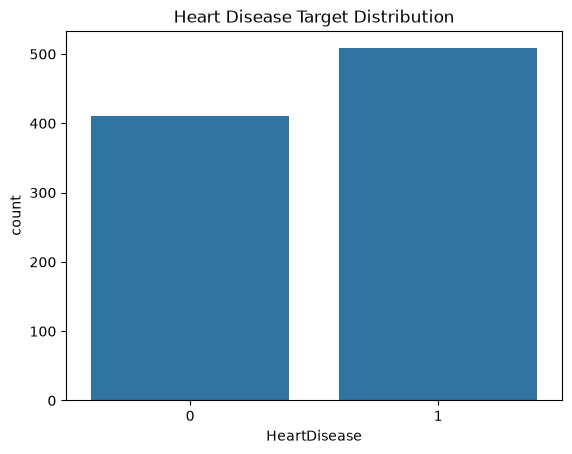

In [33]:
sns.countplot(data=df, x="HeartDisease")
plt.title("Heart Disease Target Distribution")
plt.show()

## 4. Handle invalid zero values

In this dataset, zero values in `Cholesterol` and `RestingBP` are treated as missing/invalid measurements. Replace them with the mean of the non-zero values, matching the cleaning approach used in the original notebook.

In [34]:
ch_mean = df.loc[df["Cholesterol"] != 0, "Cholesterol"].mean()
resting_bp_mean = df.loc[df["RestingBP"] != 0, "RestingBP"].mean()

df["Cholesterol"] = df["Cholesterol"].replace(0, ch_mean).round(2)
df["RestingBP"] = df["RestingBP"].replace(0, resting_bp_mean).round(2)

print("Cholesterol replacement mean:", round(ch_mean, 2))
print("RestingBP replacement mean:", round(resting_bp_mean, 2))
print(df[["Cholesterol", "RestingBP"]].describe())

Cholesterol replacement mean: 244.64
RestingBP replacement mean: 132.54
       Cholesterol   RestingBP
count   918.000000  918.000000
mean    244.636253  132.540893
std      53.318029   17.989932
min      85.000000   80.000000
25%     214.000000  120.000000
50%     244.640000  130.000000
75%     267.000000  140.000000
max     603.000000  200.000000


## 5. Exploratory data analysis

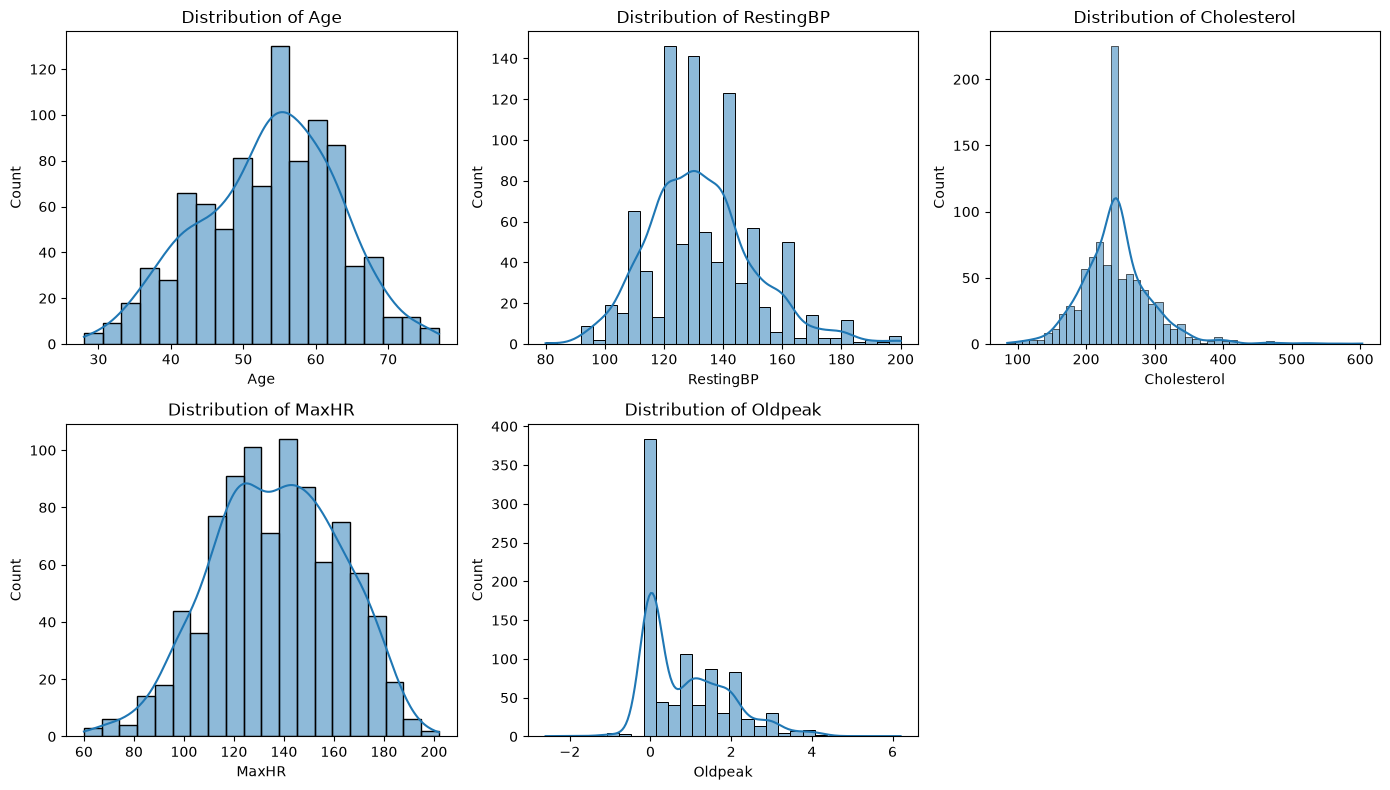

In [35]:
numeric_columns = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, column in zip(axes.flat, numeric_columns):
    sns.histplot(data=df, x=column, kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

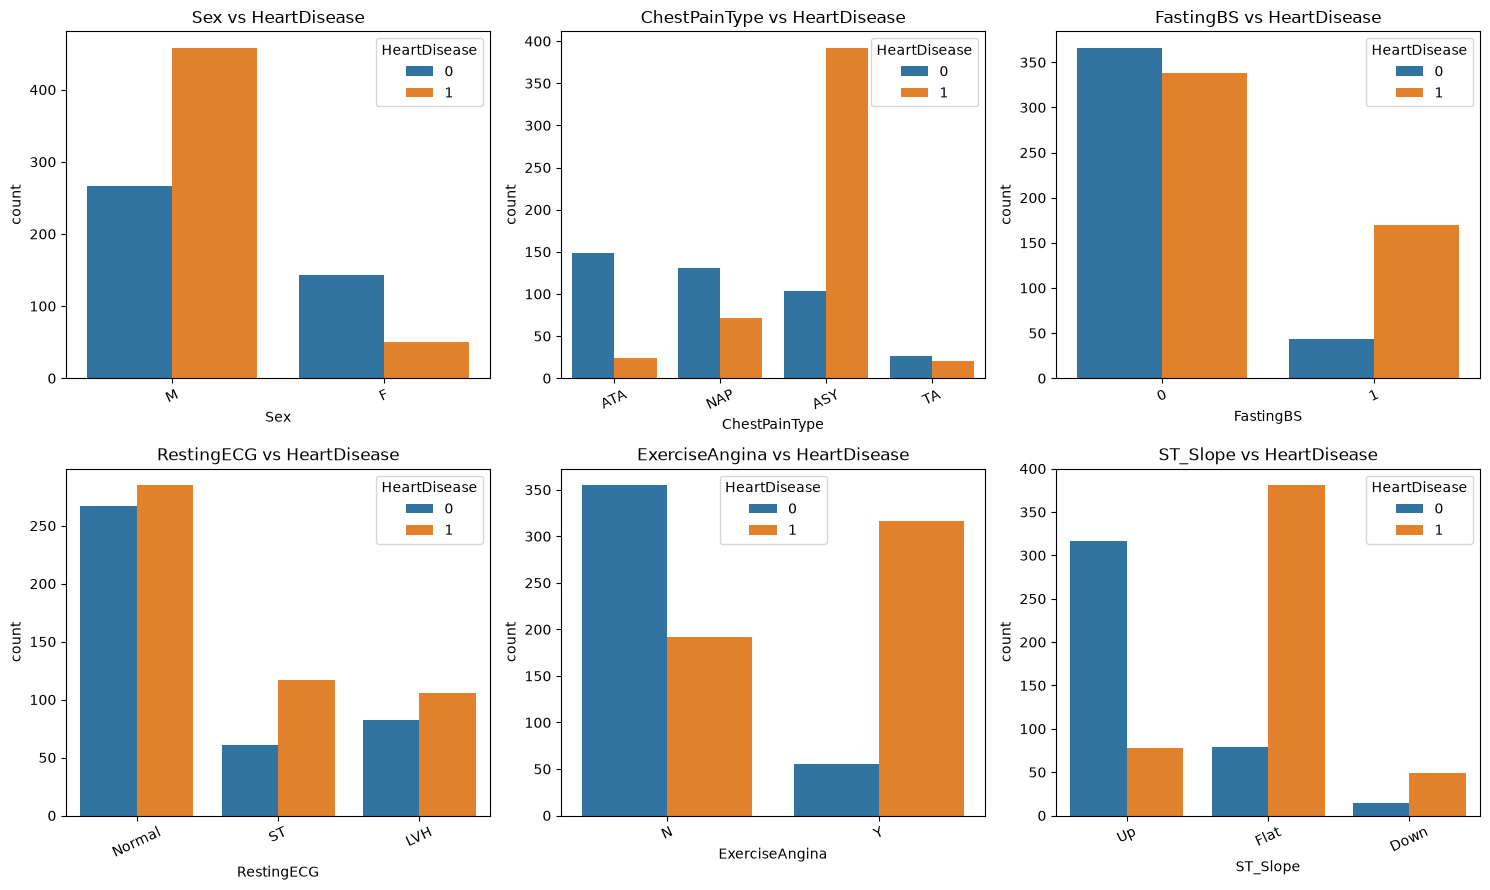

In [36]:
categorical_columns = [
    "Sex", "ChestPainType", "FastingBS",
    "RestingECG", "ExerciseAngina", "ST_Slope"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, column in zip(axes.flat, categorical_columns):
    sns.countplot(data=df, x=column, hue="HeartDisease", ax=ax)
    ax.set_title(f"{column} vs HeartDisease")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

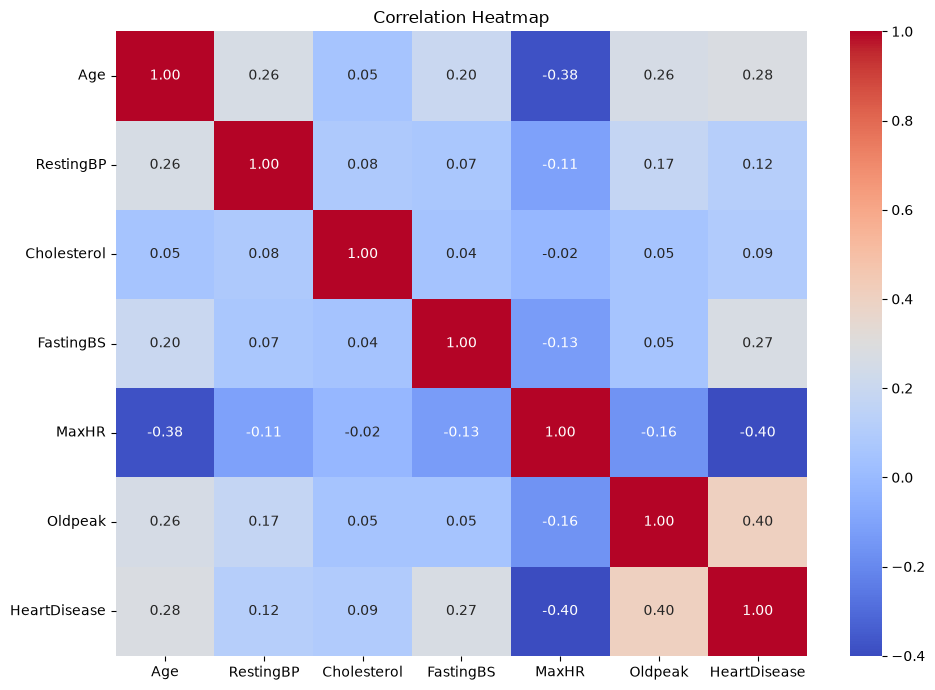

In [37]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 6. Feature engineering

Create the same engineered features that the saved model expects. The age-group boundaries are taken from the original notebook.

In [38]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 39, 49, 59, 100],
    labels=["Young", "Middle_Aged", "Older", "Senior"]
)

df["MaxHR_Percentage"] = (
    df["MaxHR"] / (220 - df["Age"])
) * 100

df["Age_Oldpeak"] = df["Age"] * df["Oldpeak"]

df[[
    "Age", "AgeGroup", "MaxHR",
    "MaxHR_Percentage", "Oldpeak", "Age_Oldpeak"
]].head()

,Age,AgeGroup,MaxHR,MaxHR_Percentage,Oldpeak,Age_Oldpeak
0,40,Middle_Aged,172,95.555556,0.0,0.0
1,49,Middle_Aged,156,91.228070,1.0,49.0
2,37,Young,98,53.551913,0.0,0.0
3,48,Middle_Aged,108,62.790698,1.5,72.0
4,54,Older,122,73.493976,0.0,0.0


## 7. Prepare features and target

One-hot encode categorical columns with `drop_first=True`. Do not convert the entire DataFrame to integers and do not scale the numerical columns. Those operations were not used to train the final GridSearchCV model.

In [39]:
X = pd.get_dummies(
    df.drop(columns=["HeartDisease"]),
    drop_first=True,
    dtype=int
)

y = df["HeartDisease"].astype(int)

print("Feature count:", X.shape[1])
print("Feature columns:")
print(X.columns.tolist())

X.head()

Feature count: 20
Feature columns:
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'MaxHR_Percentage', 'Age_Oldpeak', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up', 'AgeGroup_Middle_Aged', 'AgeGroup_Older', 'AgeGroup_Senior']


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,MaxHR_Percentage,Age_Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,AgeGroup_Middle_Aged,AgeGroup_Older,AgeGroup_Senior
0,40,140.0,289.0,0,172,0.0,95.555556,0.0,1,1,0,0,1,0,0,0,1,1,0,0
1,49,160.0,180.0,0,156,1.0,91.228070,49.0,0,0,1,0,1,0,0,1,0,1,0,0
2,37,130.0,283.0,0,98,0.0,53.551913,0.0,1,1,0,0,0,1,0,0,1,0,0,0
3,48,138.0,214.0,0,108,1.5,62.790698,72.0,0,0,0,0,1,0,1,1,0,1,0,0
4,54,150.0,195.0,0,122,0.0,73.493976,0.0,1,0,1,0,1,0,0,0,1,0,1,0


## 8. Train-test split

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 734
Testing rows: 184


## 9. Feature selection — Mutual Information

In [41]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    discrete_features=(X_train.nunique() <= 2).to_numpy(),
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": X_train.columns,
    "MI_Score": mi_scores
}).sort_values("MI_Score", ascending=False)

mi_results

,Feature,MI_Score
16,ST_Slope_Up,0.226930
15,ST_Slope_Flat,0.173418
14,ExerciseAngina_Y,0.129468
5,Oldpeak,0.118311
4,MaxHR,0.098820
9,ChestPainType_ATA,0.083652
7,Age_Oldpeak,0.071158
2,Cholesterol,0.068483
6,MaxHR_Percentage,0.066235
8,Sex_M,0.039738


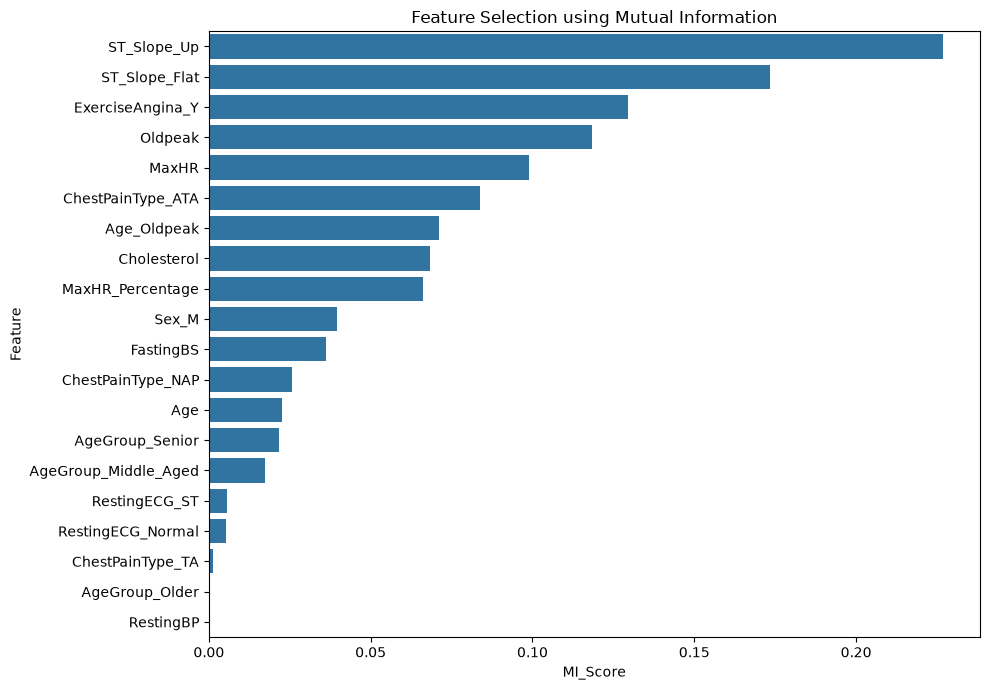

In [42]:
plt.figure(figsize=(10, 7))
sns.barplot(data=mi_results, x="MI_Score", y="Feature")
plt.title("Feature Selection using Mutual Information")
plt.tight_layout()
plt.show()

## 10. Baseline Random Forest

In [43]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

rf_importance.head(15)

,Feature,Importance
16,ST_Slope_Up,0.180118
15,ST_Slope_Flat,0.096616
5,Oldpeak,0.095723
6,MaxHR_Percentage,0.092833
4,MaxHR,0.080639
7,Age_Oldpeak,0.079176
14,ExerciseAngina_Y,0.062298
2,Cholesterol,0.058715
1,RestingBP,0.054283
0,Age,0.052329


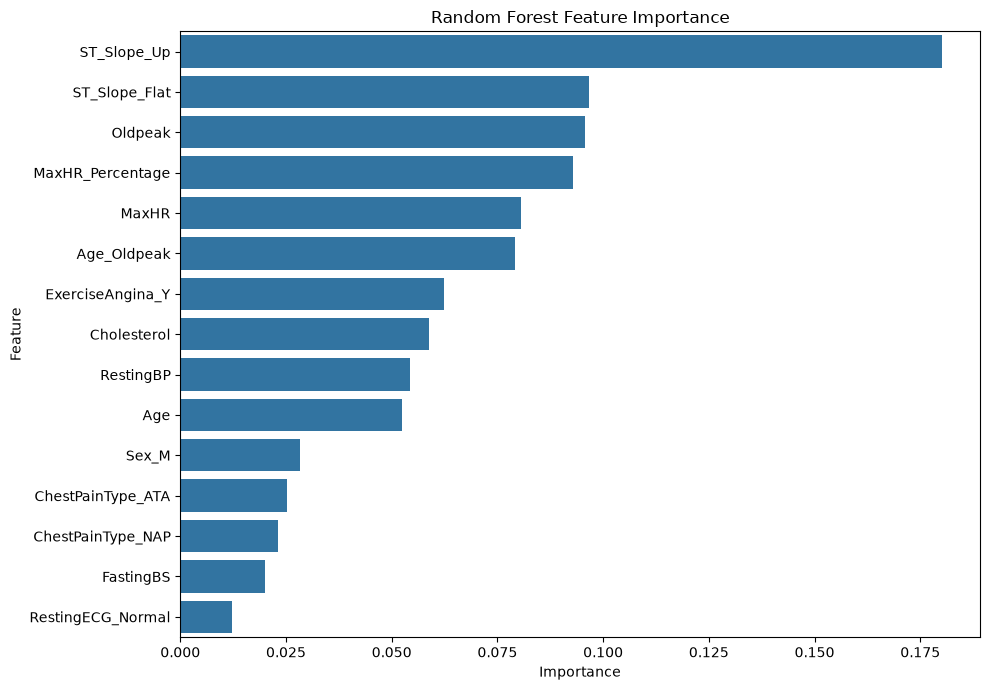

In [44]:
plt.figure(figsize=(10, 7))
sns.barplot(data=rf_importance.head(15), x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

## 11. Compare classification models

In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC()
}

results = []

for name, candidate in models.items():
    candidate.fit(X_train, y_train)
    predictions = candidate.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
results_df

,Model,Accuracy
0,Logistic Regression,0.891304
2,Random Forest,0.842391
4,SVM,0.771739
3,KNN,0.755435
1,Decision Tree,0.739130


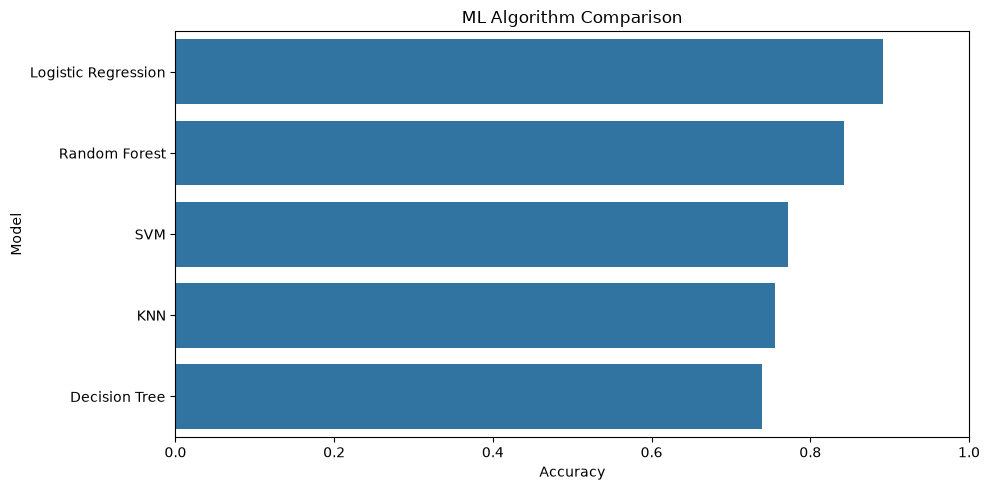

In [46]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Accuracy", y="Model")
plt.title("ML Algorithm Comparison")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## 12. Hyperparameter tuning — Random Forest

In [47]:
from sklearn.model_selection import GridSearchCV

rf_for_tuning = RandomForestClassifier(random_state=42)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf_for_tuning,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",T

In [48]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Accuracy: 0.867831516168111


## 13. Evaluate the best model

In [49]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("\\nClassification Report:")
print(classification_report(y_test, y_pred))

Test Accuracy: 0.8478260869565217
\nClassification Report:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83        82
           1       0.86      0.86      0.86       102

    accuracy                           0.85       184
   macro avg       0.85      0.85      0.85       184
weighted avg       0.85      0.85      0.85       184



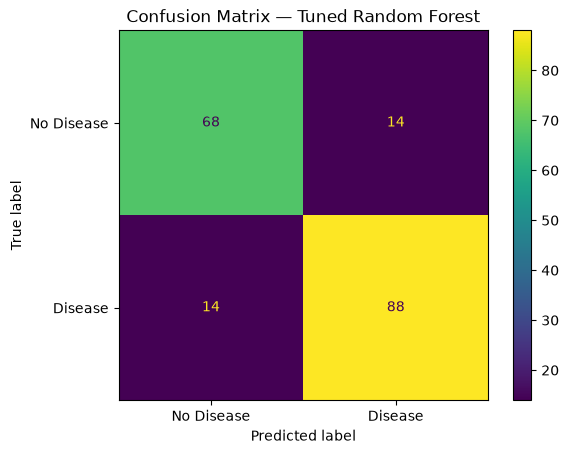

In [50]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Disease", "Disease"]).plot()
plt.title("Confusion Matrix — Tuned Random Forest")
plt.show()

## 14. Save the model artifact for FastAPI

Save the exact feature-column order and the imputation means. FastAPI will use these values to prepare incoming patient data in the same way.

In [51]:
import joblib

artifact = {
    "model": best_model,
    "feature_columns": X_train.columns.tolist(),
    "cholesterol_mean": float(ch_mean),
    "resting_bp_mean": float(resting_bp_mean),
    "age_group_bins": [0, 39, 49, 59, 100],
    "age_group_labels": ["Young", "Middle_Aged", "Older", "Senior"]
}

artifact_path = Path("heart_disease_artifact.pkl")
joblib.dump(artifact, artifact_path)

print(f"Model artifact saved to: {artifact_path.resolve()}")
print("Number of model features:", len(artifact["feature_columns"]))

Model artifact saved to: C:\Users\admin\Desktop\ML\Heart Disease prediction\notebooks\heart_disease_artifact.pkl
Number of model features: 20


## 15. Verify the saved artifact

In [53]:
loaded_artifact = joblib.load(artifact_path)

print("Artifact keys:", loaded_artifact.keys())
print("Model type:", type(loaded_artifact["model"]).__name__)
print("Number of features:", len(loaded_artifact["feature_columns"]))
print("Feature columns:")
print(loaded_artifact["feature_columns"])

Artifact keys: dict_keys(['model', 'feature_columns', 'cholesterol_mean', 'resting_bp_mean', 'age_group_bins', 'age_group_labels'])
Model type: RandomForestClassifier
Number of features: 20
Feature columns:
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'MaxHR_Percentage', 'Age_Oldpeak', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up', 'AgeGroup_Middle_Aged', 'AgeGroup_Older', 'AgeGroup_Senior']


## Important notes for deployment

1. Copy the newly saved `heart_disease_artifact.pkl` into `backend/models/`, replacing the older artifact.
2. Keep the same scikit-learn version between training and inference when possible. This notebook saves the model using the version installed in the notebook environment.
3. The API must accept the original patient inputs, replace zero measurements using the saved means, calculate `AgeGroup`, `MaxHR_Percentage`, and `Age_Oldpeak`, one-hot encode, and reindex to `feature_columns`.
4. This is an educational prediction project, not a medical diagnostic tool. Its output must not be used as a substitute for professional medical advice.